# Основные подходы машинного бучения

1. Supervised leanring (Обучение с преподавателем)

    - Regression
    - Classification

2. Unsupervised leanring (Обучение без преподавателя)

    - Clustering
    - Dimensionality Reduction
    - Anomaly detection

3. Reinforcement learning (Обучение с подкреплением)
4. Semi-Supervised learning
5. Self-Supervised learning

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline



# Процесс обучения алгоритма регрессии
1. Предоброботка данных
2. Разделения данных на обучаемых и проверочных (train/test split)
3. Выборка модели и гипрепараметров
4. Оптимизация параметров (Обучение)
5. Оценка данных
6. Более стабильная оценка данных

In [3]:
FILE_PATH = 'Housing.csv'
data = pd.read_csv(FILE_PATH)

# EDA (Exploratory Data Analysis) - Первичный анализ данных

In [4]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [5]:
data.tail()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
541,542,91500,4800.0,3,2,4,yes,yes,no,no,yes,0.0,no
542,543,94000,6000.0,3,2,4,yes,no,no,no,yes,0.0,no
543,544,103000,6000.0,3,2,4,yes,yes,no,no,yes,1.0,no
544,545,105000,6000.0,3,2,2,yes,yes,no,no,yes,1.0,no
545,546,105000,6000.0,3,1,2,yes,no,no,no,yes,1.0,no


In [6]:
data.sample(3)

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
234,235,36000,3000.0,2,1,2,yes,no,no,no,no,0.0,no
249,250,45000,3450.0,3,1,2,yes,no,yes,no,no,0.0,no
273,274,64900,4100.0,2,2,1,yes,yes,yes,no,no,0.0,no


In [7]:
data.shape

(546, 13)

In [8]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [9]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     4
fullbase    0
gashw       2
airco       7
garagepl    2
prefarea    2
dtype: int64

In [10]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


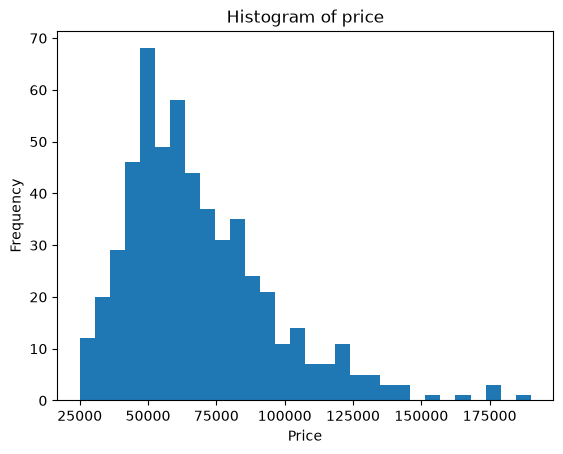

In [11]:
plt.figure()
plt.hist(data['price'], bins=30)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of price')
plt.show()

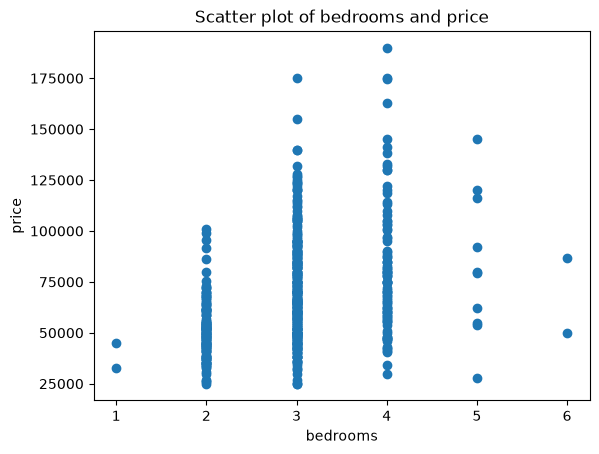

In [12]:
plt.figure()
plt.scatter(data['bedrooms'], data['price'])
plt.xlabel('bedrooms')
plt.ylabel('price')
plt.title('Scatter plot of bedrooms and price')
plt.show()

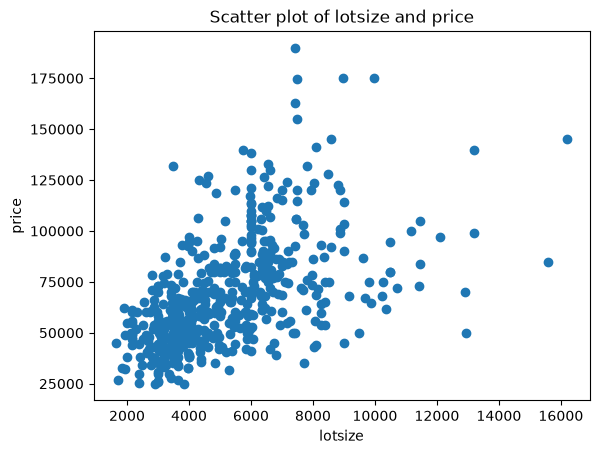

In [13]:
plt.figure()
plt.scatter(data['lotsize'], data['price'])
plt.xlabel('lotsize')
plt.ylabel('price')
plt.title('Scatter plot of lotsize and price')
plt.show()

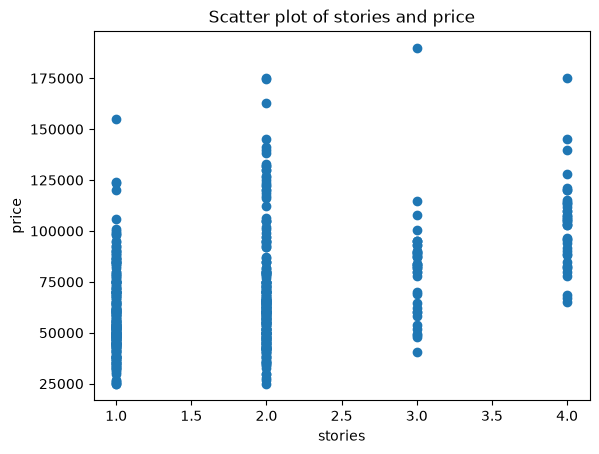

In [14]:
plt.figure()
plt.scatter(data['stories'], data['price'])
plt.xlabel('stories')
plt.ylabel('price')
plt.title('Scatter plot of stories and price')
plt.show()

In [15]:
target_column = 'price'
numeric_cols = ['lotsize', 'bedrooms', 'bathrms', 'stories', 'garagepl'] 
categorical_cols = ['driveway', 'recroom', 'fullbase', 'gashw', 'airco', 'prefarea']

In [16]:
all_used_cols = numeric_cols + categorical_cols + [target_column]
data = data[all_used_cols]

data.head()

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3,1,2,1.0,yes,no,yes,no,no,no,42000
1,4000.0,2,1,1,0.0,yes,no,no,no,no,no,38500
2,3060.0,3,1,1,0.0,yes,no,no,no,no,no,49500
3,6650.0,3,1,2,0.0,yes,yes,no,no,no,no,60500
4,6360.0,2,1,1,0.0,yes,no,no,no,no,no,61000


Factorize

In [17]:
data_factorized = data.copy()
factorize_maps = {}
for col in categorical_cols:
  codes, uniques = pd.factorize(data_factorized[col])
  data_factorized[col] = codes
  factorize_maps[col] = list(uniques)

data_factorized[categorical_cols].head()

,driveway,recroom,fullbase,gashw,airco,prefarea
0,0,0,0,0,0,0
1,0,0,1,0,0,0
2,0,0,1,0,0,0
3,0,1,1,0,0,0
4,0,0,1,0,0,0


factorize_maps

In [18]:
{'driveway': ['no', 'yes'], 
 'recroom': ['no', 'yes'], 
 'fullbase': ['no', 'yes'], 
 'gashw': ['no', 'yes'], 
 'airco': ['no', 'yes'], 
 'prefarea': ['no', 'yes']}

{'driveway': ['no', 'yes'],
 'recroom': ['no', 'yes'],
 'fullbase': ['no', 'yes'],
 'gashw': ['no', 'yes'],
 'airco': ['no', 'yes'],
 'prefarea': ['no', 'yes']}

# OHE - One Hot Encoder - One Hot кодирование

In [19]:
data_onehot = pd.get_dummies(data_factorized, columns=categorical_cols, drop_first=True)
data_onehot.head()


,lotsize,bedrooms,bathrms,stories,garagepl,price,driveway_0,driveway_1,recroom_0,recroom_1,fullbase_1,gashw_0,gashw_1,airco_0,airco_1,prefarea_0,prefarea_1
0,5850.0,3,1,2,1.0,42000,True,False,True,False,False,True,False,True,False,True,False
1,4000.0,2,1,1,0.0,38500,True,False,True,False,True,True,False,True,False,True,False
2,3060.0,3,1,1,0.0,49500,True,False,True,False,True,True,False,True,False,True,False
3,6650.0,3,1,2,0.0,60500,True,False,False,True,True,True,False,True,False,True,False
4,6360.0,2,1,1,0.0,61000,True,False,True,False,True,True,False,True,False,True,False


# Масштабирование

1. MinMaxScaler
$$
x' = \frac{x-x_{min}}{x_{max}-x_{min}}
$$
2. StandardScaler
$$
x' = \frac{x_\mu}{\sigma}
$$

In [20]:
num_demo = data[numeric_cols].copy()
mms = MinMaxScaler()
std_scaler = StandardScaler()

num_demo_ms = pd.DataFrame(mms.fit_transform(num_demo), columns=numeric_cols)
num_demo_std = pd.DataFrame(std_scaler.fit_transform(num_demo), columns=numeric_cols)


In [21]:
num_demo_ms.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl
0,0.288660,0.4,0.000000,0.333333,0.333333
1,0.161512,0.2,0.000000,0.000000,0.000000
2,0.096907,0.4,0.000000,0.000000,0.000000
3,0.343643,0.4,0.000000,0.333333,0.000000
4,0.323711,0.2,0.000000,0.000000,0.000000
5,0.172509,0.4,0.000000,0.000000,0.000000
6,0.153265,0.4,0.333333,0.333333,0.666667
7,0.172509,0.4,0.000000,0.666667,0.000000
8,0.216495,0.4,0.000000,0.000000,0.000000
9,0.264605,0.4,0.333333,1.000000,0.333333


In [22]:
num_demo_std.head(10)

,lotsize,bedrooms,bathrms,stories,garagepl
0,0.317233,0.047235,-0.569495,0.221704,0.354381
1,-0.534074,-1.310147,-0.569495,-0.931157,-0.806963
2,-0.966630,0.047235,-0.569495,-0.931157,-0.806963
3,0.685365,0.047235,-0.569495,0.221704,-0.806963
4,0.551917,-1.310147,-0.569495,-0.931157,-0.806963
5,-0.460447,0.047235,-0.569495,-0.931157,-0.806963
6,-0.589294,0.047235,1.423737,0.221704,1.515724
7,-0.460447,0.047235,-0.569495,1.374565,-0.806963
8,-0.165941,0.047235,-0.569495,-0.931157,-0.806963
9,0.156175,0.047235,1.423737,2.527427,0.354381


# SimpleImputer
- mean
- median
- most_frequent
- constant

In [23]:
data_impute_demo = data.copy()
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

data_impute_demo[numeric_cols] = num_imputer.fit_transform(data_impute_demo[numeric_cols])
data_impute_demo[categorical_cols] = cat_imputer.fit_transform(data_impute_demo[categorical_cols])
data_impute_demo.isna().sum()

lotsize     0
bedrooms    0
bathrms     0
stories     0
garagepl    0
driveway    0
recroom     0
fullbase    0
gashw       0
airco       0
prefarea    0
price       0
dtype: int64

In [24]:
data_impute_demo.head(16)

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3.0,1.0,2.0,1.0,yes,no,yes,no,no,no,42000
1,4000.0,2.0,1.0,1.0,0.0,yes,no,no,no,no,no,38500
2,3060.0,3.0,1.0,1.0,0.0,yes,no,no,no,no,no,49500
3,6650.0,3.0,1.0,2.0,0.0,yes,yes,no,no,no,no,60500
4,6360.0,2.0,1.0,1.0,0.0,yes,no,no,no,no,no,61000
5,4160.0,3.0,1.0,1.0,0.0,yes,yes,yes,no,yes,no,66000
6,3880.0,3.0,2.0,2.0,2.0,yes,no,yes,no,no,no,66000
7,4160.0,3.0,1.0,3.0,0.0,yes,no,no,no,no,no,69000
8,4800.0,3.0,1.0,1.0,0.0,yes,yes,yes,no,no,no,83800
9,5500.0,3.0,2.0,4.0,1.0,yes,yes,no,no,no,no,88500


# Feature Engineering

In [25]:
data_fe = data.copy()
data_fe['rooms_total'] = data_fe['bedrooms'] + data_fe['bathrms']
data_fe['lot_per'] = data_fe['lotsize'] / np.where(data_fe['rooms_total'] > 0, data_fe['rooms_total'],1)
data_fe[['lotsize', 'bedrooms', 'bathrms', 'rooms_total', 'lot_per']].head()

,lotsize,bedrooms,bathrms,rooms_total,lot_per
0,5850.0,3,1,4,1462.500000
1,4000.0,2,1,3,1333.333333
2,3060.0,3,1,4,765.000000
3,6650.0,3,1,4,1662.500000
4,6360.0,2,1,3,2120.000000


In [26]:
X = data_fe.drop(columns=[target_column])
y = data_fe[target_column]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_features = numeric_cols + ['rooms_total', 'lot_per']
cat_features = categorical_cols

numeric_transformer = Pipeline(

    steps=[

        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())

    ]


)


categorical_transformer = Pipeline(

    steps = [

('imputer', SimpleImputer(strategy='most_frequent')),
('onehot', OneHotEncoder())


]

)



preprocessor = ColumnTransformer(

    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)]

)



linreg_model = Pipeline(

    steps=[

        ('prepocessor', preprocessor),
        ('model', LinearRegression())
    

    ]

)



linreg_model.fit(X_train, y_train)
y_pred = linreg_model.predict(X_test)


In [27]:
y_test, y_pred

(316     80000
 77      47000
 360    130000
 90      47000
 495     59000
         ...  
 357     95000
 39      54500
 54      38000
 155     60000
 46      41000
 Name: price, Length: 110, dtype: int64,
 array([ 68262.65130676,  66463.51271943, 109719.5827139 ,  61491.38819062,
         56963.1211534 ,  59143.43175785,  56156.68608676,  55097.81735331,
         98282.41600138,  46908.20247415,  78624.52447842,  96737.28730184,
         53921.28745442,  64340.03296904,  98166.66546727, 110173.30235563,
         75193.36587532,  47474.78938319,  88541.35433401,  54639.75778248,
         35728.72178205,  48570.7461433 ,  77111.27784147,  53625.9732336 ,
         73084.31561319,  39924.37883578,  85664.33563946,  40317.74890814,
        102395.17118707,  60643.896645  ,  51480.41791298,  77440.94181427,
         72238.20668731,  91220.57035886,  57576.84411668,  51651.84021921,
         35943.97181578,  67388.12629675,  70900.95066421, 102972.19007465,
         40265.57322195, 109883.89

# Metrics

# MAE - Mean Absolute Error
$$
MAE = \frac{1}{n}\sum|y_i - \hat{y_i}|
$$
# MSE - Mean Squared Error
$$
MSE = \frac{1}{n}\sum(y_i - \hat{y_i})^2
$$
# RMSE - Root Mean Squared Error
$$
RMSE = \sqrt{MSE}
$$
# $R^2$ Score
$$
R^2 = 1 - \frac{\text{Ошибка нашей модели}}{\text{ошибка модели, которая всегда предсказывает среднее}}
$$

# Metrics (MAE, MSE, RMSE, R2_Score)


In [28]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print(f'''

MAE: {mae:.3f}
MSE: {mse:.3f}
RMSE: {rmse:.3f}
R2: {r2:.3f}


'''

)



MAE: 11178.712
MSE: 252780232.049
RMSE: 15899.064
R2: 0.622





c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\model_selection\_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\model_selection\_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\utils\validation.py", line 80, in inner_f
    return f(*args, **kwargs)
  File "c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\metrics\_scorer.py", line 328, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\User\AppData\Local\Python\pythoncore-3.15-64\Lib\s

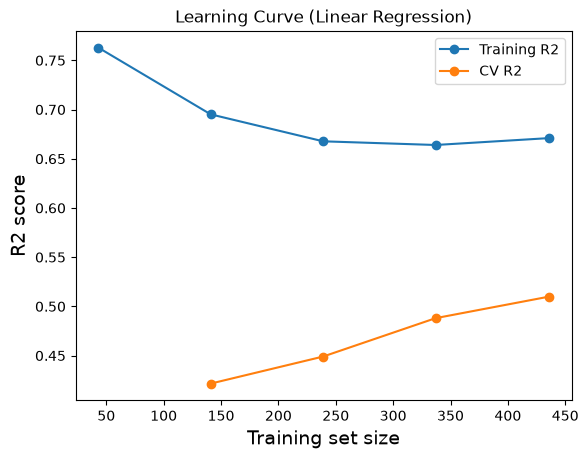

In [29]:
train_sizes, train_scores, test_scores = learning_curve(
    linreg_model,
    X,
    y,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(.1, 1.0, 5),
    n_jobs=None,
    shuffle=True,
    random_state=42)

train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

plt.figure()
plt.plot(train_sizes, train_mean, label='Training R2', marker='o')
plt.plot(train_sizes, test_mean, 'o-', label='CV R2', )
plt.title('Learning Curve (Linear Regression)')
plt.ylabel('R2 score', fontsize=14)
plt.xlabel('Training set size', fontsize=14)
plt.legend(loc='best')
plt.show()